# **Analyzing the 2026-2027 MLB Hitter Free Agent Class**
#### by Joseph Altmann

## **Introduction**
Every offseason, MLB front offices dedicate millions of dollars to players available in free agency. Signing the wrong players can be a huge setback for some teams. Typically, these players are assessed based on their performance the season prior. However, sometimes their stats may not properly highlight their skill as a player.<br>
<br>
**Purpose:** The purpose of this project is to analyze the 2026-2027 MLB hitter free agent class, and decide which players teams should target and avoid. I used Statcast data from the 2026 season to look deeper into each available free agent's expected stats, bat tracking data, and quality-of-contact numbers to separate players that may have overperformed or underperformed their expected production.<br>
<br>
**Scope:** This analysis only covers qualified hitters in the 2026 season. Defensive numbers and pitchers are not being considered.<br>
<br>
**Data:** The free agent list came from mlbtraderumors.com, which I typed into a .csv file. Player performance data comes from Baseball Savant (Statcast), pulled with the `pybaseball` package. Only hitters with enough plate appearances and tracked swings to qualify are included.

## **Research Questions**
**Question 1:** Which free agent hitters over- or underperformed their expected stats in 2026?<br>
**Question 2:** Which free agent hitters have the underlying contact quality to sustain their production?<br>
**Question 3:** How does age affect the risk of signing each player?

## **Statistics Overview**
**wOBA (Weighted On Base Average):** A version of on-base percentage that accounts for how a player reached base instead of simply considering whether a player reached base.<br>
**Avg (Batting Average):** Determined by dividing a player's hits by his total at-bats for a number between zero and one.<br>
**xwOBA / xAvg (Expected Stats):** What a player's wOBA and batting average should have been, based on quality of contact (exit velocity and launch angle, plus sprint speed on some batted balls) rather than actual results. A gap between actual and expected suggests luck.<br>
**Barrel %:** Measures the percentage of a player's batted-ball events that have been classified as "barrels"—balls hit with the optimal combination of exit velocity and launch angle.<br>
**Average Bat Speed:** The velocity of the bat's sweet spot at the exact point of contact with the ball.<br>
**Sweet Spot %:** Measures how often a hitter produces a batted ball with a launch angle between 8 and 32 degrees.<br>
**Average Exit Velocity:** Measures the mean speed of a batted ball immediately after a hitter makes contact with the pitch.

In [1]:
## == Imports ==
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pybaseball import (
playerid_lookup,
statcast_batter_expected_stats,
statcast_batter_bat_tracking,
statcast_batter_exitvelo_barrels
)

In [16]:
## == Read CSV file ==
df = pd.read_csv("free_agents_data.csv")

## == Add player ID to dataset ==
# Each player has an ID associated with their stats
# This looks up the ID of each player in the dataset file
# Used ClaudeAI to assist with this function
def get_player_id(first, last):
    try:
        result = playerid_lookup(last, first)
        if not result.empty:
            result = result.sort_values("mlb_played_last", ascending=False)
            return result.iloc[0]["key_mlbam"]
    except Exception as e:
        print(f"Could not find {first} {last}: {e}")
    return None

# Adds each player's ID to the dataset
df["xMLBAMID"] = df.apply(lambda row: get_player_id(row["first_name"], row["last_name"]), axis=1)

In [3]:
## == Pull necessary stats ==
expected_stats = statcast_batter_expected_stats(2026, minPA='q')
bat_tracking = statcast_batter_bat_tracking(2026)
barrel_stats = statcast_batter_exitvelo_barrels(2026, minBBE='q')

In [4]:
## == Add stats to each player in the dataset ==
hitters_df = (df
    .merge(expected_stats, left_on = "xMLBAMID", right_on = 'player_id', how = 'left')
    .merge(bat_tracking, left_on = 'xMLBAMID', right_on = 'id', how = 'left')
    .merge(barrel_stats, left_on = 'xMLBAMID', right_on = 'player_id', how = 'left')
)

In [5]:
## == Drop hitters without statcast bat tracking data ==
qualified_hitters_df = hitters_df.dropna(subset=['avg_bat_speed'])

In [6]:
## == Drop unnecessary columns ==
# Create list of columns to drop
columns_to_drop = [
    'last_name',
    'first_name',
    'xMLBAMID',
    'year',
    'id',
    'name',
    'swing_tilt',
    'attack_angle',
    'attack_direction',
    'avg_intercept_y_vs_plate',
    'avg_intercept_y_vs_batter',
    'avg_batter_y_position',
    'avg_batter_x_position',
    'competitive_swings',
    'last_name, first_name_y',
    'player_id_y',
    'attempts',
    'avg_hit_angle',
    'gb'
]

# Drop all columns in the list created above
qualified_hitters_df = qualified_hitters_df.drop(columns = columns_to_drop)

In [7]:
## == Rename the column used for player name for easier access ==
qualified_hitters_df = qualified_hitters_df.rename(columns={'last_name, first_name_x': 'player_name'})

In [8]:
## == Create a column for xwoba - woba ==
# This allows us to easily view who overperformed and underperformed
qualified_hitters_df['woba_diff'] = qualified_hitters_df['est_woba'] - qualified_hitters_df['woba']

In [9]:
## == Create a dataset with only the top 10 and bottom 10 in xwoba - woba differential ==
top_woba_diff = pd.concat([
    qualified_hitters_df.nlargest(10, 'woba_diff'),
    qualified_hitters_df.nsmallest(10, 'woba_diff').sort_values('woba_diff', ascending=False)
])

### **Market Overview**

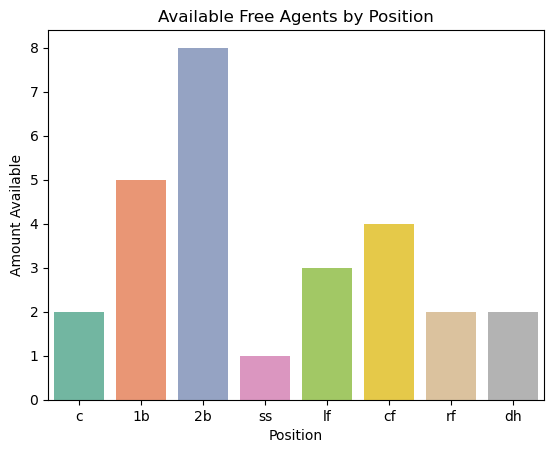

In [10]:
## == Create a barplot with the available free agents at each position ==
# This gives us a good view of the market 
# Positions with less available free agents may have higher priority to sign
sns.countplot(data=qualified_hitters_df, x='position', hue='position', palette='Set2')

plt.title("Available Free Agents by Position")
plt.xlabel("Position")
plt.ylabel("Amount Available")
plt.show()

## **Question 1:** Which free agent hitters over- or underperformed their expected stats in 2026?
A hitter's actual results can be pushed around by luck, such as a hard-hit ball right at a fielder or a soft one that drops in. Expected stats (xwOBA and xAvg) strip that out by measuring the quality of each batted ball instead of what happened. Comparing the two shows who was lucky and who was unlucky.

The charts below compare actual and expected values in three ways:

- **Scatterplots (wOBA and Avg):** Actual is on the x-axis and expected is on the y-axis. A hitter above the diagonal line had better expected numbers than actual results, so he **underperformed** and may be undervalued. A hitter below the line had better results than his contact quality supports, so he **overperformed** and may be due for a decline. The farther from the line, the bigger the gap.
- **Bar chart:** The 10 biggest underperformers and 10 biggest overperformers by xwOBA minus wOBA.


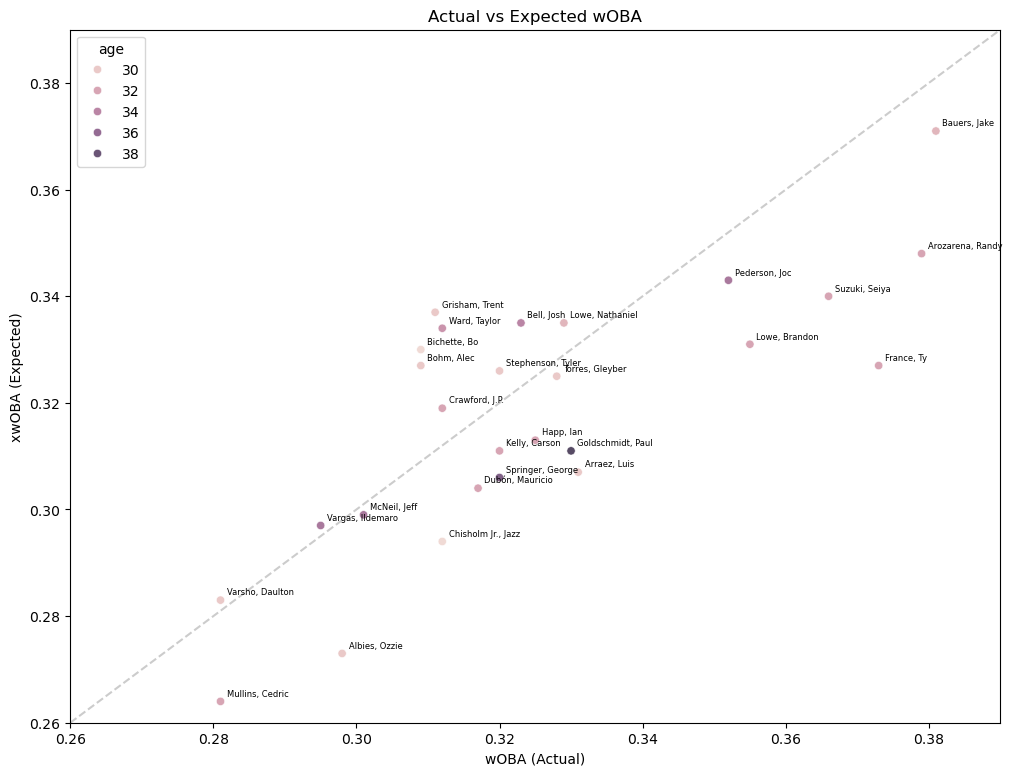

In [11]:
## == Create a scatterplot comparing actual and expected wOBA ==
# This will allow us to view what players were overperforming and underperforming
# Hitters below the centerline overperformed, while hitters above underperformed
# The further a hitter is from the line, the more they over- or underperformed
plt.figure(figsize=(12, 9))
sns.set_palette('viridis_r')
sns.scatterplot(data=qualified_hitters_df, x='woba', y='est_woba', hue='age', alpha=.8)

for index, row in qualified_hitters_df.iterrows():
    plt.annotate(row['player_name'], 
                (row['woba'] + .0009, row['est_woba'] + .001),
                 fontsize = 6)

plt.title('Actual vs Expected wOBA')
plt.xlabel('wOBA (Actual)')
plt.ylabel('xwOBA (Expected)')
plt.xlim(.26, .39)
plt.ylim(.26, .39)
plt.plot([.26, .39], [.26, .39], color='grey', linestyle='--', alpha=.4)
plt.show()

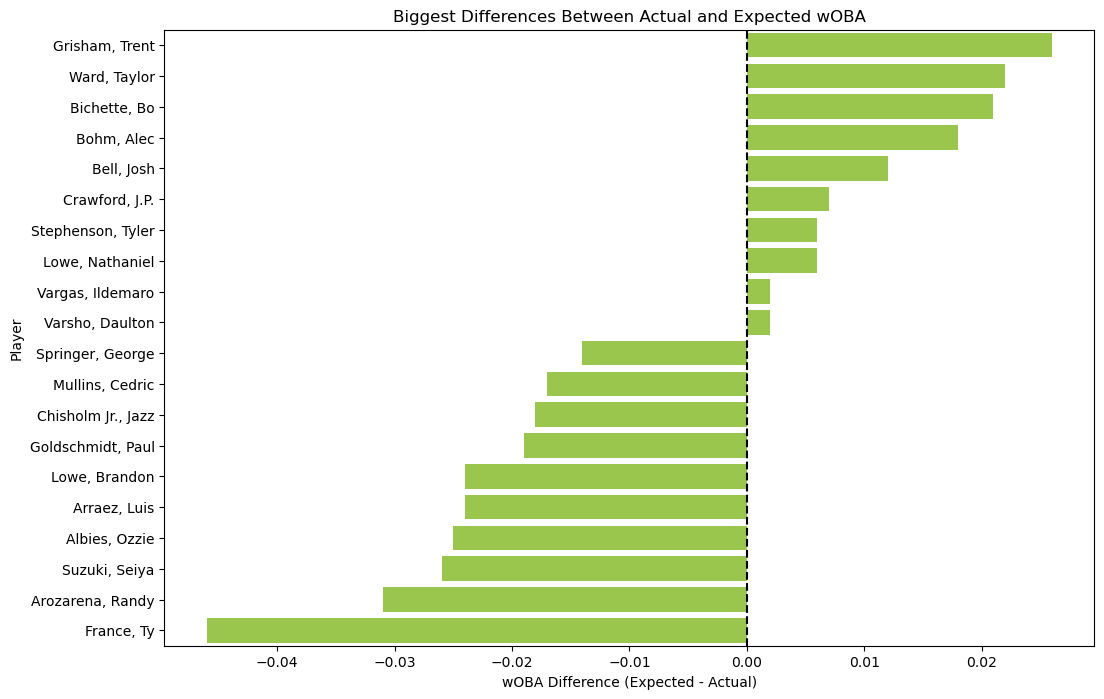

In [12]:
## == Bargraph showing the top 10 and bottom 10 in actual and expected wOBA differential ==
# This allows us to easily look at what players overperformed and underperformed the most
plt.figure(figsize=(12, 8))

sns.barplot(data=top_woba_diff, x='woba_diff', y='player_name')

plt.axvline(0, color='black', linestyle='--')
plt.title('Biggest Differences Between Actual and Expected wOBA')
plt.xlabel('wOBA Difference (Expected - Actual)')
plt.ylabel('Player')

plt.show()

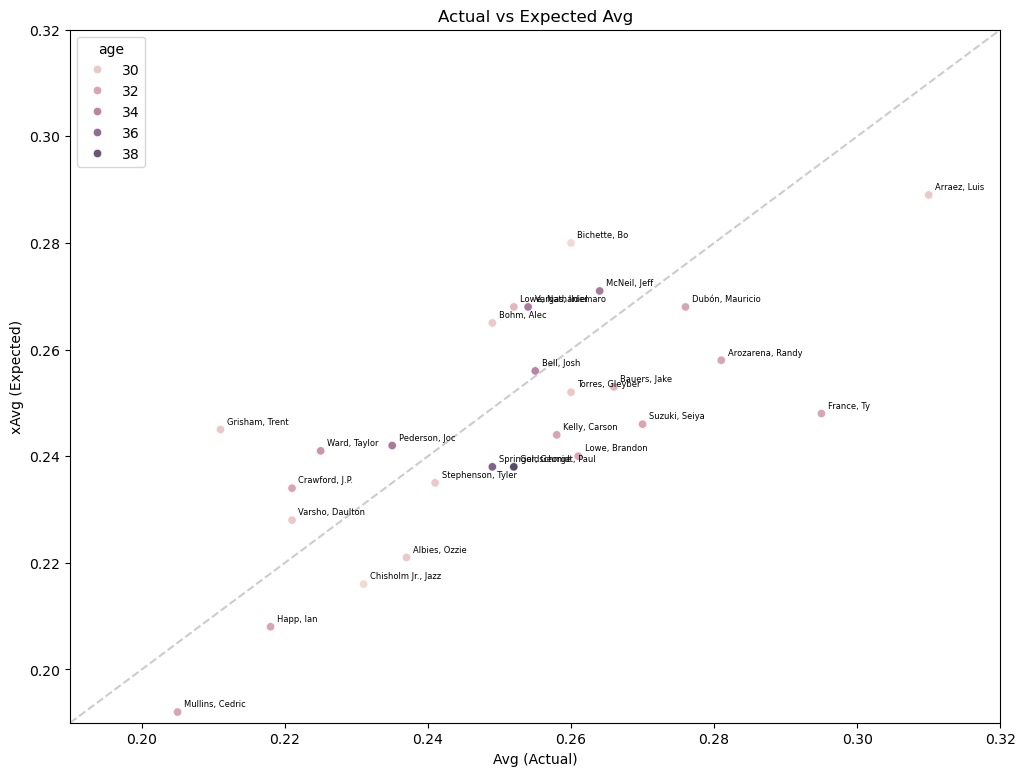

In [13]:
## == Create a scatterplot comparing actual and expected Avg ==
# This will allow us to view what players were got more or fewer hits than expected
# Hitters below the centerline overperformed, while hitters above underperformed
# The further a hitter is from the line, the more they over- or underperformed
plt.figure(figsize=(12, 9))
sns.set_palette('viridis_r')
sns.scatterplot(data=qualified_hitters_df, x='ba', y='est_ba', hue='age', alpha=.8)

for index, row in qualified_hitters_df.iterrows():
    plt.annotate(row['player_name'], 
                (row['ba'] + .0009, row['est_ba'] + .001),
                 fontsize = 6)

plt.title('Actual vs Expected Avg')
plt.xlabel('Avg (Actual)')
plt.ylabel('xAvg (Expected)')
plt.xlim(.19, .32)
plt.ylim(.19, .32)
plt.plot([.19, .32], [.19, .32], color='grey', linestyle='--', alpha=.4)
plt.show()

### **Question 1 Takeaways**

**Biggest underperformers:** Trent Grisham, Taylor Ward, and Bo Bichette had the largest gaps between expected and actual wOBA. Their quality of contact suggests their 2026 results undersold their ability, which makes them candidates to sign.

**Biggest overperformers:** Ty France, Randy Arozarena, and Seiya Suzuki produced well above what their contact quality supports. Their results may not repeat, which makes them candidates to avoid.

**Caveat:** This is one season of data, so some of these gaps may shrink or grow next year. Question 2 checks whether each player's underlying skills support his production.

## **Question 2:** Which free agent hitters have the underlying contact quality to sustain their production?

Question 1 showed who got lucky or unlucky, but expected stats are still built from results. This question looks at the skills behind those results: how hard a hitter swings, how often he squares the ball up, and how hard and at what angle he hits it. Hitters who do these things well are more likely to keep producing.

The two charts below each pair two measures of contact quality:

- **Barrel % vs. average bat speed:** Shows who swings the bat hard and also produces ideal batted balls consistently.
- **Average exit velocity vs. sweet spot %:** Shows who hits the ball hard and at productive launch angles.

In both charts, the best hitters are closest to the top-right corner. Hitters in the bottom-left have the weakest contact quality.

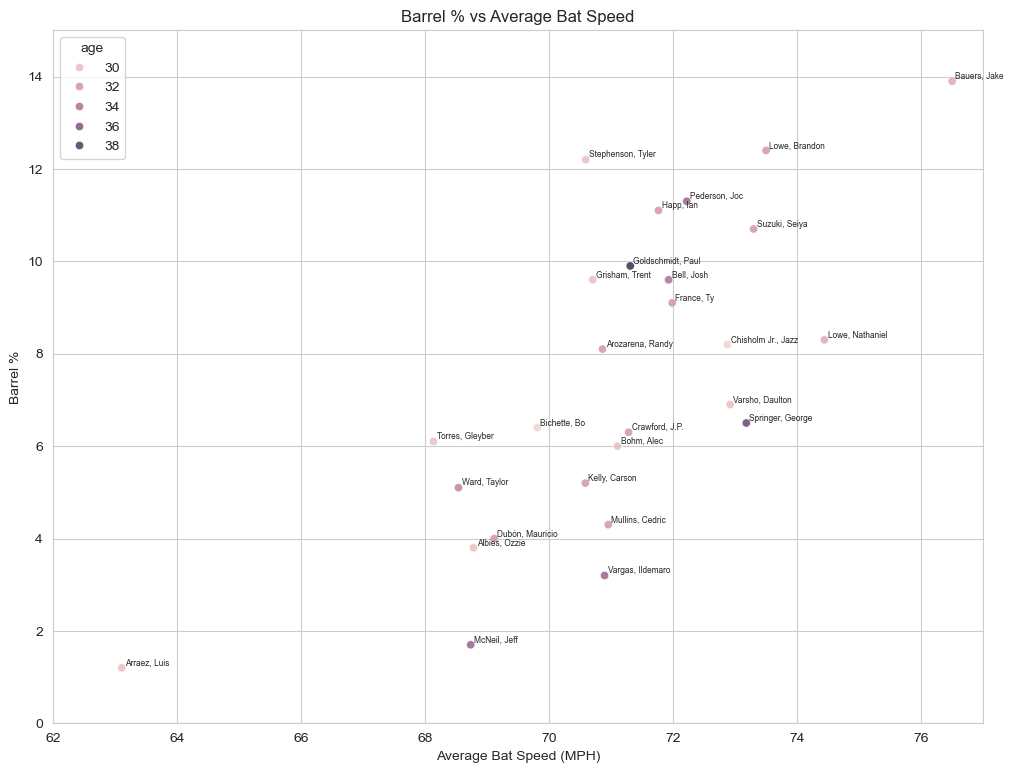

In [14]:
## == Create a scatterplot showing Barrel Percentage vs Average Bat Speed ==
# This allows us to view what hitters are swinging the bat hard, with consistent ideal batted balls
# The best hitters should be closest to the top right corner of the graph
plt.figure(figsize=(12, 9))
sns.set_style("whitegrid")
sns.set_palette('viridis_r')
sns.scatterplot(data=qualified_hitters_df, x='avg_bat_speed', y='brl_percent', hue='age', alpha=.8)

for index, row in qualified_hitters_df.iterrows():
    plt.annotate(row['player_name'], 
                (row['avg_bat_speed'] + .05, row['brl_percent'] + .05),
                 fontsize = 6)

plt.title('Barrel % vs Average Bat Speed')
plt.xlabel('Average Bat Speed (MPH)')
plt.ylabel('Barrel %')
plt.xlim(62, 77)
plt.ylim(0, 15)
plt.show()

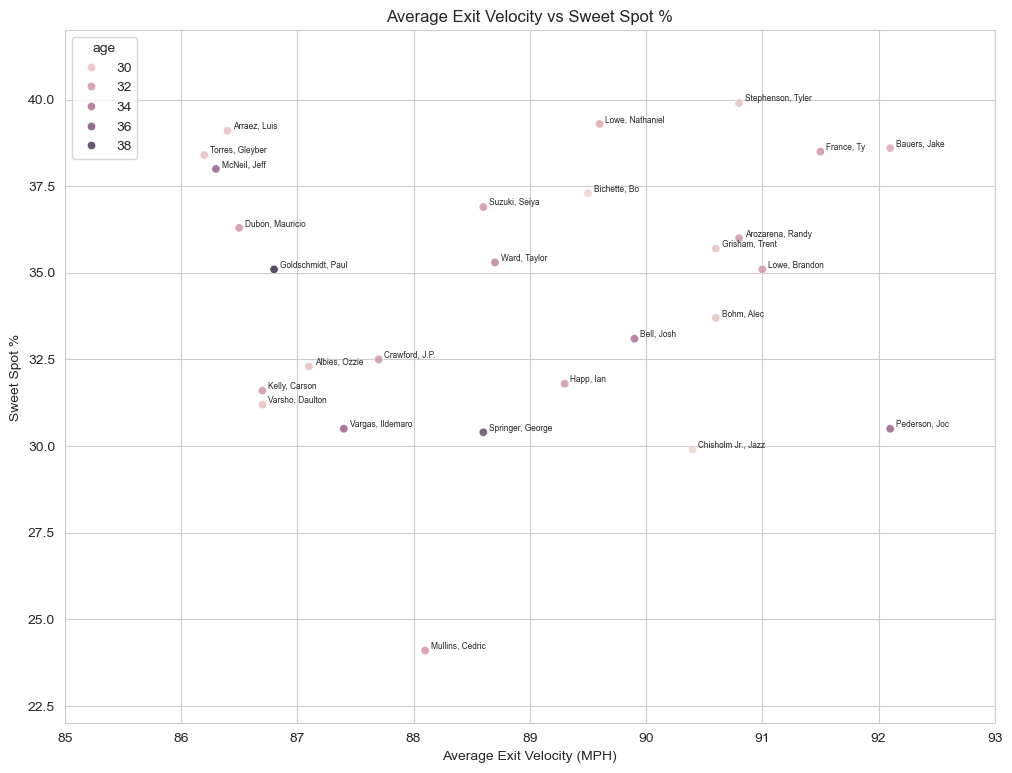

In [15]:
## == Create a scatterplot showing Average Exit Velocity vs Sweet Spot Percentage ==
# This allows us to view what hitters hit the ball hard, and in the most ideal direction
# The best hitters should be closest to the top right corner of the graph
plt.figure(figsize=(12, 9))
sns.set_style("whitegrid")
sns.set_palette('viridis_r')
sns.scatterplot(data=qualified_hitters_df, x='avg_hit_speed', y='anglesweetspotpercent', hue='age', alpha=.8)

for index, row in qualified_hitters_df.iterrows():
    plt.annotate(row['player_name'], 
                (row['avg_hit_speed'] + .05, row['anglesweetspotpercent'] + .05),
                 fontsize = 6)

plt.title('Average Exit Velocity vs Sweet Spot %')
plt.xlabel('Average Exit Velocity (MPH)')
plt.ylabel('Sweet Spot %')
plt.xlim(85, 93)
plt.ylim(22, 42)
plt.show()

### **Question 2 Takeaways**

**Strongest contact quality:** Jake Bauers, Brandon Lowe, and Tyler Stephenson sit near the top right of both charts. Their production looks sustainable.


## **Question 3:** How does age affect the risk of signing each player?
Free agent contracts often run several years, and hitters generally lose bat speed and power as they age. That makes age a major part of any signing decision: a player with great numbers at 28 and one with the same numbers at 36 are very different investments.

This section looks at how age lines up with performance in this free agent class. It focuses on two things:

- **Whether the best hitters skew young or old**, by comparing expected production (xwOBA) and contact quality (bat speed, barrel %) across age groups.
- **Whether older hitters are leaning on results their contact quality doesn't support**, by comparing the gap between actual and expected wOBA across age groups.

Because this notebook uses a single season, it can't measure how any player will age. It only shows where age risk is concentrated in this class.<br>
We can use the previous graphs to analyze this.

### **Question 3 Takeaways**

**Age and quality:** The strongest underlying hitters in this class are spread across age groups.

**Highest-risk players:** George Springer (37) and Paul Goldschmidt (39) are the clearest age risks. Both are 37 or older and had results above their expected stats.

**Lowest-risk players:** Bo Bichette (28) and Trent Grisham (30) are 30 or younger with strong contact quality and results that trailed their expected stats, so their production looks both real and likely to last.

**Caveat:** These are one-season patterns in a small group of players, and they show where age risk is concentrated in this class, not how any individual will age.

# **Conclusion:** Who to sign and who to avoid?
This project set out to separate free agent hitters who earned their 2026 production from those who may have gotten lucky. Using expected stats, contact quality, and age, I identified three hitters teams should target and three they should avoid.
<br>
<br>
### **Players to Target**
**1. Bo Bichette (3rd Baseman/Shortstop, 28)** <br>
In his first season with the New York Mets, Bichette's xwOBA and xAvg were much higher than his actual results indicated. Although his barrel % was not among the top of the free agent class, his sweet spot % was among some of the highest of available free agents. At only 28 years old, he is expected to continue to be productive as opposed to some of his fellow free agents who may be older. There is a chance he does not opt out of his current contract with the New York Mets, but if he decides to decline, he becomes a strong candidate for any team needing an infielder.

**2. Jake Bauers (1st Baseman, 31)** <br>
Although Bauers' xAvg is lower than what his actual Avg showed, his xwOBA and underlying contact quality rank among the top of all free agents. His xwOBA was lower than his actual wOBA, but both are still the highest ranks for all available free agents. A slight dip in his elite production will still make him a highly productive hitter. He also has by far the highest barrel % and average bat speed among available free agents, as well as being among the highest for sweet spot % and average exit velocity. At 31 years old, he will be able to sustain his elite production for years to come. He should be a primary target for any team in need of a first baseman.

**3. Trent Grisham (Outfielder, 30)** <br>
Grisham had one of the largest gaps in this free agent class between his expected and actual production, with an xwOBA about .025 points above his wOBA and an xAvg about .03 points above his actual average. Also, Grisham showed good underlying contact quality numbers for all of the selected stats, being near the top right of both graphs. At 30 years old, he can be expected to sustain strong production going forward. Any team in need of an outfielder should circle Trent Grisham as a target this offseason.
<br>
<br>
### **Players to Avoid** 
**1. Randy Arozarena (Outfielder, 31)** <br>
Arozarena is 31 years old, so he could be expected to continue his production going forward. However, his xwOBA and xAvg were much lower than his actual production showed. He also does not have elite average bat speed or barrel % to sustain his elite production. Although he is expected to still sustain positive offensive production, it may not be as high as his numbers showed this year.

**2. Ty France (1st Baseman, 32)** <br>
France had by far the largest negative difference between his xwOBA and actual wOBA, at about -0.04. His actual Avg was also significantly higher than his xAvg. Although he showed some of the best average exit velocity and sweet spot % numbers among available free agents, his differentials in his expected and actual production are too alarming to ignore. The juxtaposition between elite quality of contact and poor expected stats makes his profile complicated, but a dip in production is still expected. Teams looking for a first baseman should be cautious unless they are willing to bet that his production holds up despite running well ahead of his expected stats.

**3. Paul Goldschmidt (1st Baseman/DH, 39)** <br>
Goldschmidt had one of the largest differentials in expected stats and actual production, having a difference between xwOBA and actual wOBA at about -0.02. Goldschmidt ranks toward the bottom in average exit velocity, and at 39 years old, his average bat speed is likely to drop year after year. Although his sweet spot % and barrel % numbers are solid, his age and poor expected stats are big red flags. In a strong first base market, teams have more promising options available.

## **Limitations and Next Steps**

### **Limitations**
- **One season of data:** All findings come from 2026, so a lucky or unlucky year carries a lot of weight. Some gaps between expected and actual production may shrink or grow next season.
- **Hitters only:** Pitchers were not analyzed, so this covers only part of the free agent class.
- **No defense or contract cost:** A player's overall value depends on defense, and a good signing depends on price. Neither is included here.
- **Age analysis is descriptive:** The data shows how age lines up with performance in this class but can't predict how individual players will age.
- **Qualification filter:** Players without enough tracked swings were removed, which means some free agents were not evaluated.

### **Next Steps**
- Add multiple seasons to see whether the expected-vs-actual gaps persist.
- Include pitchers and defensive metrics for a fuller picture.
- Add contract estimates and team needs to identify the best fits and likely landing spots.